In [37]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import pennylane as qml
import matplotlib.pyplot as plt

print("numpy:", np.__version__)
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("pennylane:", qml.__version__)


numpy: 2.4.6
torch: 2.11.0
cuda available: False
pennylane: 0.45.0


In [38]:
DATA_PATH = "data/ml-100k/u.data"   
OUT_DIR = "models/qprior_movielens"
os.makedirs(OUT_DIR, exist_ok=True)

# Q-Prior settings
n_qubits = 3              # 2^3 = 8 states for 5 rating bins
num_layers = 8
epochs = 200
lr = 0.01
seed = 42

np.random.seed(seed)
torch.manual_seed(seed)

num_states = 2 ** n_qubits
num_ratings = 5
assert num_states >= num_ratings


## 2. Load recommender data

This section loads ratings and shows basic dataset statistics.

In [39]:
def load_movielens_u_data(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Could not find {path}. Update DATA_PATH to your u.data file."
        )
    data = np.loadtxt(path, delimiter="	", dtype=np.int64)
    df = pd.DataFrame(data, columns=["user_id", "item_id", "rating", "timestamp"])
    return df

ratings_df = load_movielens_u_data(DATA_PATH)
ratings_df.head()


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [40]:
print("Number of ratings:", len(ratings_df))
print("Number of users:", ratings_df["user_id"].nunique())
print("Number of items:", ratings_df["item_id"].nunique())
print("Rating values:", sorted(ratings_df["rating"].unique()))

ratings_df["rating"].describe()


Number of ratings: 100000
Number of users: 943
Number of items: 1682
Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

## 3. Empirical rating distribution

This is the classical target distribution that the Q-Prior will learn.

In [41]:
rating_values = np.arange(1, 6)
counts = ratings_df["rating"].value_counts().sort_index().reindex(rating_values, fill_value=0).values.astype(np.float32)
empirical_prior = counts / counts.sum()

empirical_table = pd.DataFrame({
    "rating": rating_values,
    "count": counts.astype(int),
    "empirical_probability": empirical_prior,
})
empirical_table


,rating,count,empirical_probability
0,1,6110,0.06110
1,2,11370,0.11370
2,3,27145,0.27145
3,4,34174,0.34174
4,5,21201,0.21201


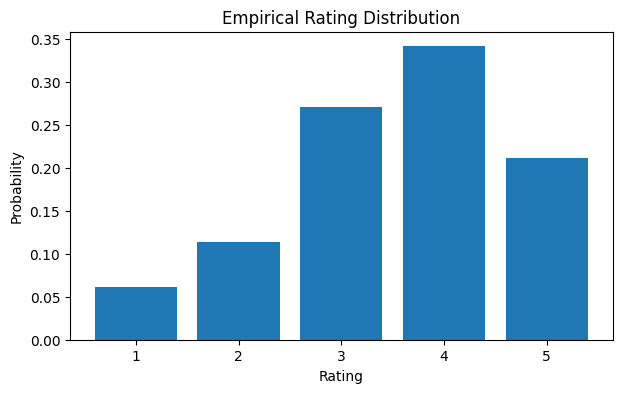

In [42]:
plt.figure(figsize=(7, 4))
plt.bar(rating_values, empirical_prior)
plt.xlabel("Rating")
plt.ylabel("Probability")
plt.title("Empirical Rating Distribution")
plt.xticks(rating_values)
plt.show()


## 4. quantum generator

Only the first five basis states are mapped to ratings 1–5. Any remaining states are ignored and the first five probabilities are renormalized.

In [43]:
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qprior_circuit(params):
    for layer in range(num_layers):
        for i in range(n_qubits):
            qml.RY(params[layer, i, 0], wires=i)
            qml.RZ(params[layer, i, 1], wires=i)
            qml.RX(params[layer, i, 2], wires=i)

        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i + 1])

    return qml.probs(wires=range(n_qubits))

class RatingQPrior(nn.Module):
    def __init__(self):
        super().__init__()
        self.params = nn.Parameter(0.01 * torch.randn(num_layers, n_qubits, 3))

    def forward(self):
        probs = qprior_circuit(self.params)
        rating_probs = probs[:num_ratings]
        rating_probs = rating_probs / rating_probs.sum()
        return rating_probs

model = RatingQPrior()
print(model)


RatingQPrior()


## 5. Train Q-Prior

The loss mirrors your KS script's MMD-style direct distribution loss:

```text
loss = sum((qprior_probs - empirical_rating_probs)^2)
```

For a prelim experiment this is simple, stable, and easy to visualize.

In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
target_probs = torch.tensor(empirical_prior, dtype=torch.float32, device=device)

optimizer = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.99))
loss_history = []
prior_history = []

start_time = time.time()

for epoch in range(epochs):
    optimizer.zero_grad()
    pred_probs = model()
    loss = torch.sum((pred_probs - target_probs) ** 2)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    prior_history.append(pred_probs.detach().cpu().numpy())

    if epoch % 50 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:04d} | loss = {loss.item():.8f}")

elapsed = time.time() - start_time
print(f"Training time: {elapsed:.2f} seconds")


Epoch 0000 | loss = 1.12785965
Epoch 0050 | loss = 0.00321223
Epoch 0100 | loss = 0.00001091
Epoch 0150 | loss = 0.00000004
Epoch 0199 | loss = 0.00000000
Training time: 2.61 seconds


## 6. Inspect the learned Q-Prior

In [45]:
learned_prior = model().detach().cpu().numpy()

comparison = pd.DataFrame({
    "rating": rating_values,
    "empirical_prior": empirical_prior,
    "learned_qprior": learned_prior,
    "absolute_error": np.abs(empirical_prior - learned_prior),
})
comparison


,rating,empirical_prior,learned_qprior,absolute_error
0,1,0.06110,0.061093,0.000007
1,2,0.11370,0.113705,0.000005
2,3,0.27145,0.271458,0.000008
3,4,0.34174,0.341730,0.000010
4,5,0.21201,0.212015,0.000005


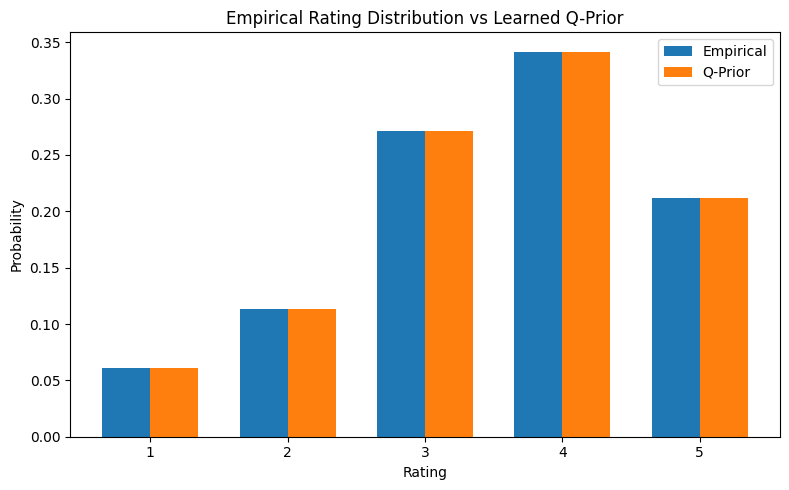

In [46]:
plt.figure(figsize=(8, 5))
width = 0.35
plt.bar(rating_values - width/2, empirical_prior, width=width, label="Empirical")
plt.bar(rating_values + width/2, learned_prior, width=width, label="Q-Prior")
plt.xlabel("Rating")
plt.ylabel("Probability")
plt.title("Empirical Rating Distribution vs Learned Q-Prior")
plt.xticks(rating_values)
plt.legend()
plt.tight_layout()
plt.show()


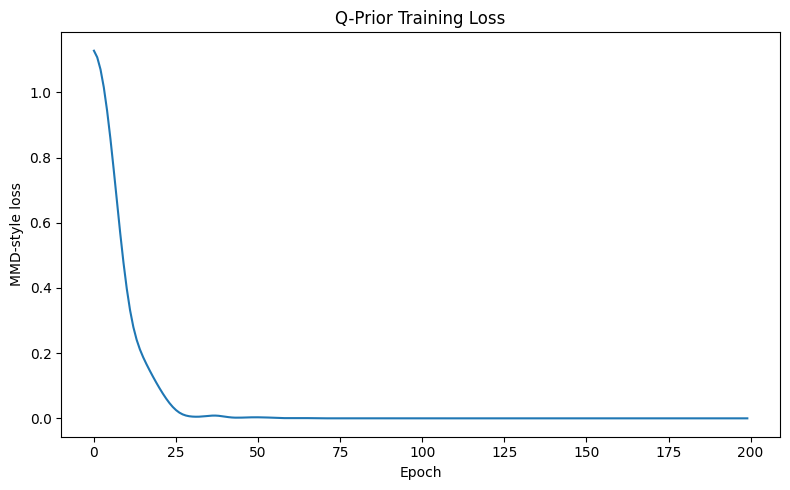

In [47]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MMD-style loss")
plt.title("Q-Prior Training Loss")
plt.tight_layout()
plt.show()


## 7. Inspect probability evolution during training

This helps diagnose whether the quantum generator is converging smoothly to the rating histogram.

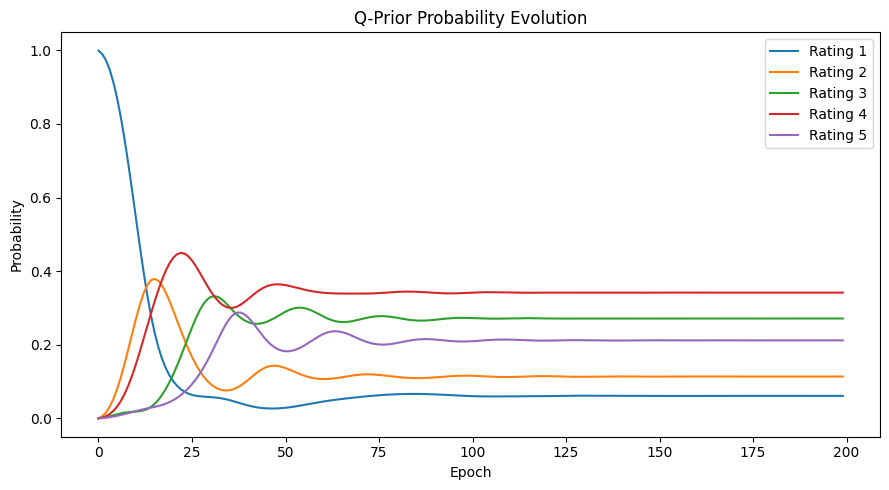

In [48]:
prior_history_arr = np.array(prior_history)  # shape: epochs x 5

plt.figure(figsize=(9, 5))
for idx, rating in enumerate(rating_values):
    plt.plot(prior_history_arr[:, idx], label=f"Rating {rating}")
plt.xlabel("Epoch")
plt.ylabel("Probability")
plt.title("Q-Prior Probability Evolution")
plt.legend()
plt.tight_layout()
plt.show()


## 8. full quantum state probabilities

For 3 qubits, there are 8 basis states. States 0–4 are mapped to ratings 1–5; states 5–7 are unused in this basic version.

In [49]:
with torch.no_grad():
    full_probs = qprior_circuit(model.params).detach().cpu().numpy()

basis_labels = [format(i, f"0{n_qubits}b") for i in range(num_states)]
full_state_table = pd.DataFrame({
    "basis_state": basis_labels,
    "state_index": np.arange(num_states),
    "raw_probability": full_probs,
    "mapped_rating": [i + 1 if i < 5 else "unused" for i in range(num_states)]
})
full_state_table


,basis_state,state_index,raw_probability,mapped_rating
0,000,0,0.050580,1
1,001,1,0.094139,2
2,010,2,0.224746,3
3,011,3,0.282926,4
4,100,4,0.175532,5
5,101,5,0.103762,unused
6,110,6,0.065046,unused
7,111,7,0.003270,unused


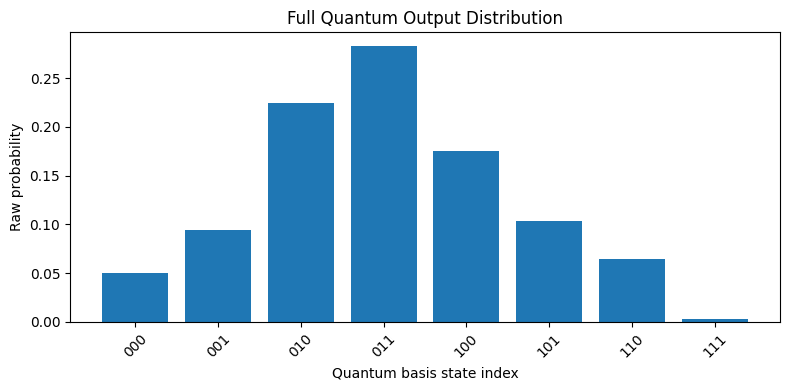

In [50]:
plt.figure(figsize=(8, 4))
plt.bar(np.arange(num_states), full_probs)
plt.xlabel("Quantum basis state index")
plt.ylabel("Raw probability")
plt.title("Full Quantum Output Distribution")
plt.xticks(np.arange(num_states), basis_labels, rotation=45)
plt.tight_layout()
plt.show()


## 9. Save Q-Prior outputs

In [51]:
qprior_path = os.path.join(OUT_DIR, "rating_qprior.npy")
model_path = os.path.join(OUT_DIR, "rating_qprior_model.pt")
comparison_path = os.path.join(OUT_DIR, "rating_qprior_comparison.csv")

np.save(qprior_path, learned_prior)
torch.save(model.state_dict(), model_path)
comparison.to_csv(comparison_path, index=False)

print("Saved:")
print(qprior_path)
print(model_path)
print(comparison_path)


Saved:
models/qprior_movielens/rating_qprior.npy
models/qprior_movielens/rating_qprior_model.pt
models/qprior_movielens/rating_qprior_comparison.csv
